# Bagging and Boosting for Classification

This notebook reads a **labeled (supervised) dataset** and classifies it using ensemble methods:

- **Bagging:** `BaggingClassifier` (decision trees) and `RandomForestClassifier`
- **Boosting:** `AdaBoostClassifier`, `GradientBoostingClassifier` and `HistGradientBoostingClassifier`
- A single **Decision Tree** is included as a baseline

Performance is reported with accuracy, precision, recall, F1, ROC-AUC, confusion matrices, ROC curves and 5-fold cross-validation.

## 1. Imports

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, HistGradientBoostingClassifier)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_curve)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Load the dataset

Set `DATA_PATH` to your CSV and `TARGET_COL` to the name of the label column.  
If `DATA_PATH` is `None` or missing, the built-in **Breast Cancer Wisconsin** dataset is used so the notebook runs end-to-end.

In [ ]:
import os
from sklearn.datasets import load_breast_cancer

DATA_PATH = None        # <-- e.g. "my_data.csv"
TARGET_COL = "target"   # <-- name of the label column in your CSV

if DATA_PATH and os.path.exists(DATA_PATH):
    df = pd.read_csv(DATA_PATH)
    print(f"Loaded {DATA_PATH}")
else:
    df = load_breast_cancer(as_frame=True).frame
    TARGET_COL = "target"
    print("Using sample dataset (Breast Cancer Wisconsin)")

print("Shape:", df.shape)
df.head()

Using sample dataset (Breast Cancer Wisconsin)
Shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


## 3. Explore

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

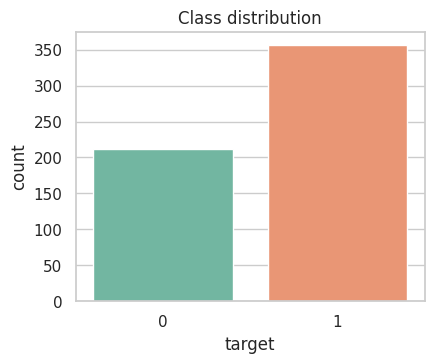

target
1    0.627
0    0.373
Name: proportion, dtype: float64


In [ ]:
df.info()
print("\nMissing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

plt.figure(figsize=(4.5, 3.5))
sns.countplot(x=df[TARGET_COL], palette="Set2")
plt.title("Class distribution"); plt.show()
print(df[TARGET_COL].value_counts(normalize=True).round(3))

## 4. Prepare the data

- Drop duplicates, fill missing values (median for numeric, mode for categorical)
- One-hot encode categorical features and label-encode the target
- Stratified 80/20 train/test split

Tree-based ensembles don't need feature scaling.

In [ ]:
df = df.drop_duplicates().copy()

y_raw = df[TARGET_COL]
X = df.drop(columns=[TARGET_COL])

# Handle missing values
for c in X.columns:
    if X[c].dtype.kind in "biufc":
        X[c] = X[c].fillna(X[c].median())
    else:
        X[c] = X[c].fillna(X[c].mode().iloc[0])

X = pd.get_dummies(X, drop_first=True)            # encode categorical features

le = LabelEncoder()
y = le.fit_transform(y_raw)
class_names = [str(c) for c in le.classes_]
n_classes = len(class_names)
print("Classes:", class_names, "| Features:", X.shape[1])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "Test:", X_test.shape)

Classes: ['0', '1'] | Features: 30
Train: (455, 30) Test: (114, 30)


## 5. Define the models

**Bagging** trains many models in parallel on bootstrap samples and averages their votes, which reduces variance.  
**Boosting** trains models sequentially, each one focusing on the errors of the previous, which reduces bias.

In [ ]:
models = {
    "Decision Tree (baseline)": DecisionTreeClassifier(random_state=RANDOM_STATE),

    # --- Bagging ---
    "Bagging (Decision Trees)": BaggingClassifier(
        estimator=DecisionTreeClassifier(), n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),

    # --- Boosting ---
    "AdaBoost": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1), n_estimators=200, learning_rate=0.5,
        random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200, learning_rate=0.1, max_depth=3, random_state=RANDOM_STATE),
    "HistGradient Boosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}

family = {"Decision Tree (baseline)": "Baseline", "Bagging (Decision Trees)": "Bagging",
          "Random Forest": "Bagging", "AdaBoost": "Boosting",
          "Gradient Boosting": "Boosting", "HistGradient Boosting": "Boosting"}

## 6. Train and evaluate on the test set

In [ ]:
avg = "binary" if n_classes == 2 else "weighted"
results, fitted, probas = [], {}, {}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)
    fitted[name], probas[name] = model, proba

    auc = (roc_auc_score(y_test, proba[:, 1]) if n_classes == 2
           else roc_auc_score(y_test, proba, multi_class="ovr", average="weighted"))
    results.append({
        "Model": name, "Type": family[name],
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, average=avg),
        "Recall": recall_score(y_test, pred, average=avg),
        "F1": f1_score(y_test, pred, average=avg),
        "ROC-AUC": auc,
    })

results_df = pd.DataFrame(results).set_index("Model")
results_df.round(4).style.background_gradient(cmap="Greens", subset=["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"])

,Type,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,,
Decision Tree (baseline),Baseline,0.912300,0.955900,0.902800,0.928600,0.915700
Bagging (Decision Trees),Bagging,0.938600,0.945200,0.958300,0.951700,0.992700
Random Forest,Bagging,0.956100,0.958900,0.972200,0.965500,0.993100
AdaBoost,Boosting,0.956100,0.946700,0.986100,0.966000,0.984800
Gradient Boosting,Boosting,0.956100,0.946700,0.986100,0.966000,0.989700
HistGradient Boosting,Boosting,0.973700,0.960000,1.000000,0.979600,0.993100


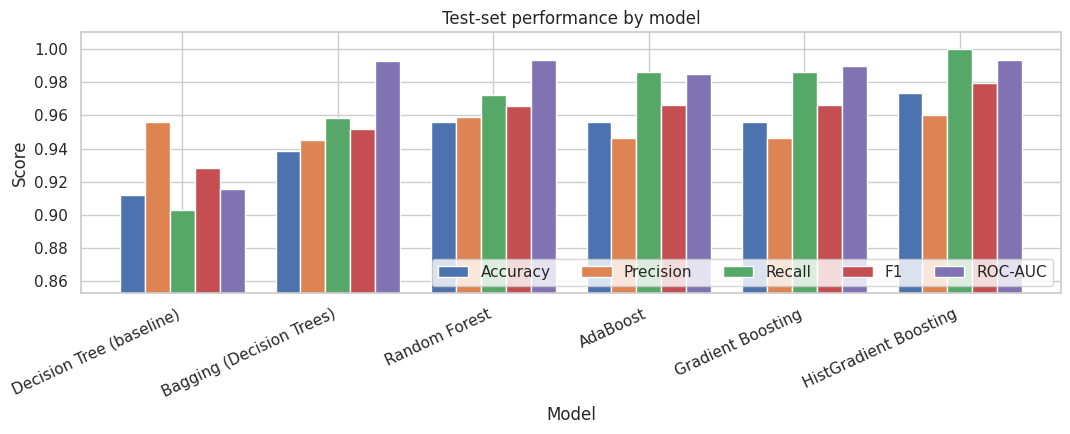

In [ ]:
# Side-by-side bar chart of the metrics
results_df[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].plot(
    kind="bar", figsize=(11, 4.5), width=0.8)
plt.ylim(max(0, results_df.iloc[:, 1:].min().min() - 0.05), 1.01)
plt.title("Test-set performance by model"); plt.ylabel("Score")
plt.xticks(rotation=25, ha="right"); plt.legend(loc="lower right", ncol=5)
plt.tight_layout(); plt.show()

## 7. Cross-validation (more reliable than a single split)

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy", n_jobs=-1)
    cv_rows.append({"Model": name, "CV Mean Accuracy": scores.mean(), "CV Std": scores.std()})
cv_df = pd.DataFrame(cv_rows).set_index("Model")
cv_df.round(4)

,CV Mean Accuracy,CV Std
Model,,
Decision Tree (baseline),0.9104,0.0279
Bagging (Decision Trees),0.9543,0.0179
Random Forest,0.9543,0.0102
AdaBoost,0.9613,0.0181
Gradient Boosting,0.9579,0.0244
HistGradient Boosting,0.9578,0.0179


## 8. Confusion matrices

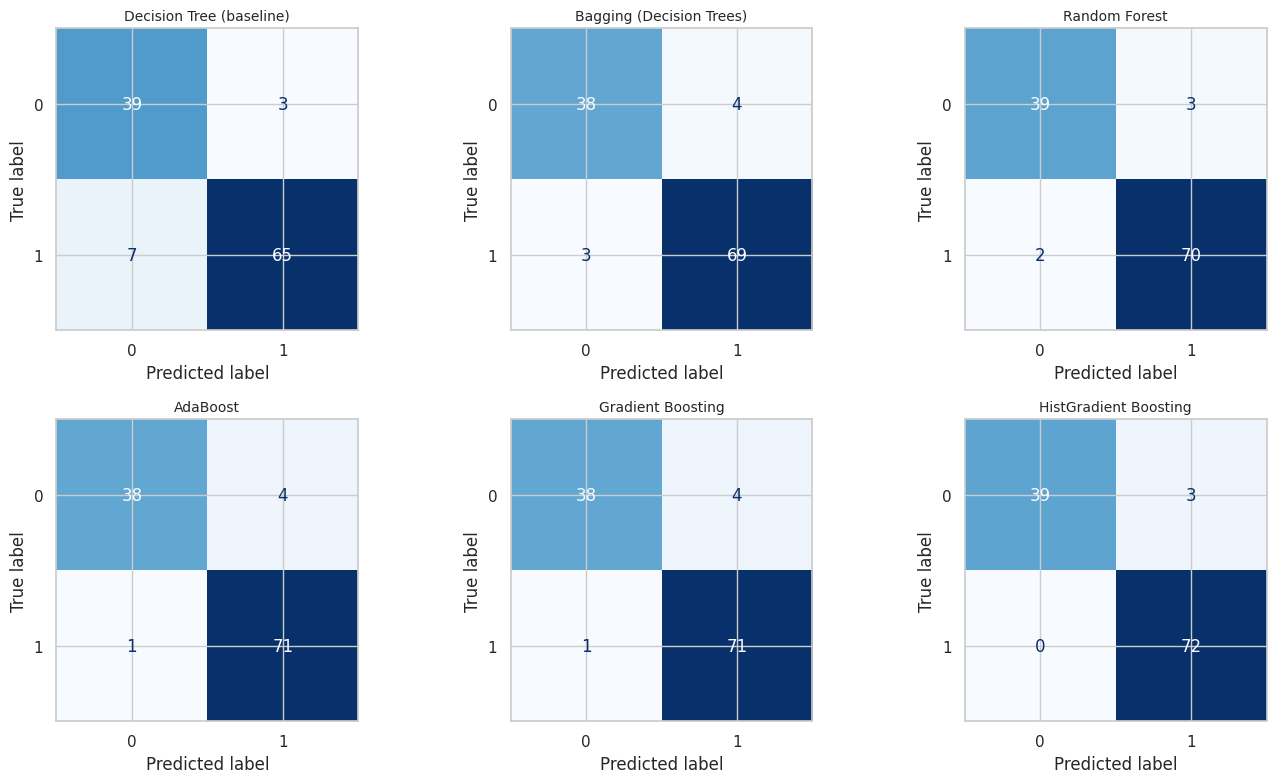

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (name, model) in zip(axes.ravel(), fitted.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name, fontsize=10)
plt.tight_layout(); plt.show()

## 9. ROC curves

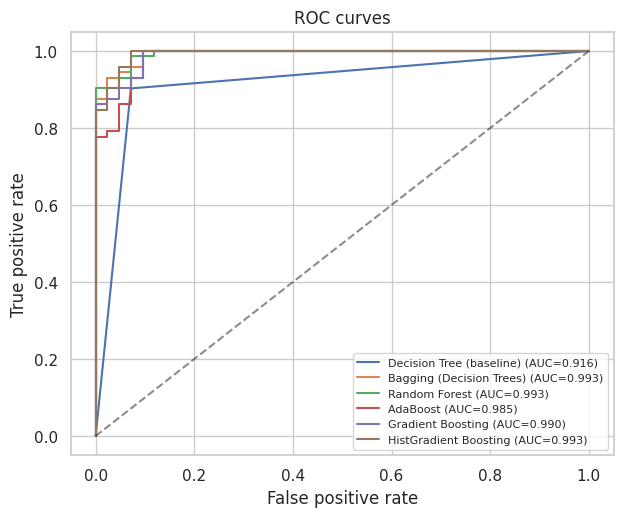

In [ ]:
if n_classes == 2:
    plt.figure(figsize=(7, 5.5))
    for name in fitted:
        fpr, tpr, _ = roc_curve(y_test, probas[name][:, 1])
        plt.plot(fpr, tpr, label=f"{name} (AUC={results_df.loc[name, 'ROC-AUC']:.3f})")
    plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
    plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
    plt.title("ROC curves"); plt.legend(loc="lower right", fontsize=8); plt.show()
else:
    print("ROC curve plot shown for binary problems only; weighted one-vs-rest AUC is in the table above.")

## 10. Best model: detailed report and feature importance

In [ ]:
best_name = results_df["F1"].idxmax()
best = fitted[best_name]
print(f"Best model by test F1: {best_name}\n")
print(classification_report(y_test, best.predict(X_test), target_names=class_names, digits=4))

Best model by test F1: HistGradient Boosting

              precision    recall  f1-score   support

           0     1.0000    0.9286    0.9630        42
           1     0.9600    1.0000    0.9796        72

    accuracy                         0.9737       114
   macro avg     0.9800    0.9643    0.9713       114
weighted avg     0.9747    0.9737    0.9735       114



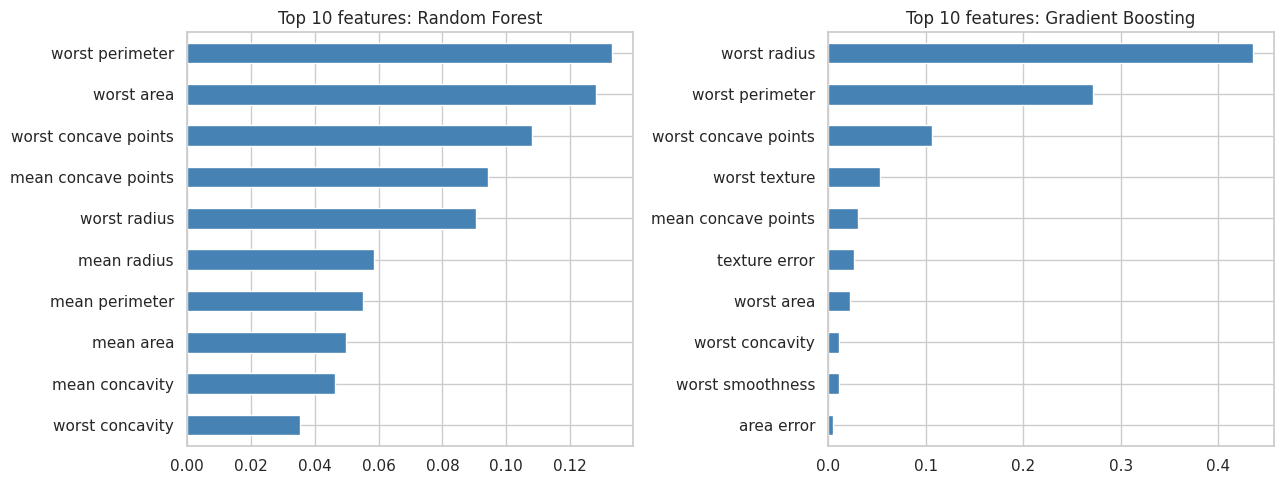

In [ ]:
# Feature importance from a bagging model (Random Forest) and a boosting model (Gradient Boosting)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, name in zip(axes, ["Random Forest", "Gradient Boosting"]):
    imp = pd.Series(fitted[name].feature_importances_, index=X.columns).nlargest(10).sort_values()
    imp.plot(kind="barh", ax=ax, color="steelblue")
    ax.set_title(f"Top 10 features: {name}")
plt.tight_layout(); plt.show()

## 11. Summary

In [ ]:
summary = results_df.join(cv_df).sort_values("F1", ascending=False).round(4)
display(summary)

grp = results_df.groupby("Type")[["Accuracy", "F1", "ROC-AUC"]].mean().round(4)
print("\nAverage by technique family:")
display(grp)

,Type,Accuracy,Precision,Recall,F1,ROC-AUC,CV Mean Accuracy,CV Std
Model,,,,,,,,
HistGradient Boosting,Boosting,0.9737,0.9600,1.0000,0.9796,0.9931,0.9578,0.0179
AdaBoost,Boosting,0.9561,0.9467,0.9861,0.9660,0.9848,0.9613,0.0181
Gradient Boosting,Boosting,0.9561,0.9467,0.9861,0.9660,0.9897,0.9579,0.0244
Random Forest,Bagging,0.9561,0.9589,0.9722,0.9655,0.9931,0.9543,0.0102
Bagging (Decision Trees),Bagging,0.9386,0.9452,0.9583,0.9517,0.9927,0.9543,0.0179
Decision Tree (baseline),Baseline,0.9123,0.9559,0.9028,0.9286,0.9157,0.9104,0.0279



Average by technique family:


,Accuracy,F1,ROC-AUC
Type,,,
Bagging,0.9474,0.9586,0.9929
Baseline,0.9123,0.9286,0.9157
Boosting,0.9620,0.9705,0.9892


## Notes

- **Bagging** (Bagging, Random Forest) mainly lowers variance, so it improves unstable models such as a single deep tree.
- **Boosting** (AdaBoost, Gradient Boosting) builds learners sequentially to reduce bias and is often the most accurate, though it is more sensitive to noisy labels and needs tuning.
- Differences of a fraction of a percent on one split can be noise, so compare the cross-validation columns too.
- **Imbalanced classes:** prefer F1, recall and ROC-AUC over accuracy, and consider `class_weight="balanced"` or resampling.
- **Your own data:** set `DATA_PATH` and `TARGET_COL`, and remove ID columns before section 4.